# Partie 1 : Le réseau de métro et RER (IDFM)

In [1]:
# ===== IMPORTS =====
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pretraitement_donnees import (
    charger_trips, charger_parcours,
    construire_lignes_idfm, charger_arrets, charger_stations,
)

In [2]:
# NEW 

# ===== FONCTION : CHARGER LES LIGNES (MÉTRO, RER, TRANSILIEN, TRAM) =====
def charger_routes_etendu(path, modes=("metro", "rer", "transilien", "tram")):
    """Comme charger_routes (pretraitement_donnees.py), avec le Transilien et le tram en plus.
    modes : les types de lignes à garder"""
    df_routes = pd.read_csv(
        f"{path}/routes.txt",
        usecols=["route_id", "route_type", "route_short_name",
                 "route_color", "route_text_color", "agency_id"],
    )

    # On ajoute le nom de l'opérateur de chaque ligne (RATP, RER, Transilien, TER...)
    agences = pd.read_csv(f"{path}/agency.txt", usecols=["agency_id", "agency_name"])
    df_routes = df_routes.merge(agences, on="agency_id")

    # On donne un type à chaque ligne
    conditions = [
        df_routes["route_type"] == 1,                                                # métro
        (df_routes["route_type"] == 2) & (df_routes["agency_name"] == "RER"),        # RER
        (df_routes["route_type"] == 2) & (df_routes["agency_name"] == "Transilien"), # Transilien
        df_routes["route_type"] == 0,                                                # tram
    ]
    df_routes["mode"] = np.select(conditions, ["metro", "rer", "transilien", "tram"], default="autre")
    # -> les TER tombent dans "autre" et sont donc écartés

    # On retire le CDG VAL (navette interne de l'aéroport de Roissy)
    df_routes = df_routes[df_routes["route_short_name"] != "CDG VAL"]

    # Couleur grise pour les lignes qui n'en ont pas
    df_routes["route_color"] = df_routes["route_color"].fillna("888888")

    return df_routes[df_routes["mode"].isin(modes)]

In [3]:
#NEW 

# ===== CHARGEMENT DES DONNÉES IDFM =====
# Lignes -> trains -> tracés -> arrêts -> stations
df_routes = charger_routes_etendu("data/idfm")          # métro, RER, Transilien, tram
df_trips = charger_trips("data/idfm", df_routes)        # trains de chaque ligne
df_parcours = charger_parcours("data/idfm", df_trips)   # points GPS des tracés
gpd_idfm = construire_lignes_idfm(df_parcours)          # tracés en Lambert 93 (mètres)
df_arrets = charger_arrets("data/idfm", df_trips)       # arrêts desservis par ligne
df_stations = charger_stations("data/idfm", df_arrets)  # position des stations

# Stations transformées en points géographiques, en mètres (Lambert 93)
gpd_stations = gpd.GeoDataFrame(
    df_stations,
    geometry=gpd.points_from_xy(df_stations["stop_lon"], df_stations["stop_lat"]),
    crs="EPSG:4326",
).to_crs("EPSG:2154")

# Vérification : les lignes gardées, par type
df_routes.groupby("mode")["route_short_name"].apply(list)

mode
metro         [1, 2, 3, 14, 3B, 7B, 7, 13, 4, 5, 6, 8, 9, 10...
rer                                             [A, B, C, D, E]
tram          [T9, T4, ORLYVAL, T5, T11, T6, T8, T3b, T3a, T...
transilien                          [R, U, P, N, H, K, J, L, V]
Name: route_short_name, dtype: object

In [4]:
# ===== ORDRE DES STATIONS LE LONG DE CHAQUE LIGNE =====

# Tracé de référence : pour chaque ligne, le tracé le plus long (le "mètre ruban")
gpd_idfm["longueur"] = gpd_idfm.length
traces = gpd_idfm.sort_values("longueur", ascending=False).drop_duplicates("route_id")
trace_ref = pd.DataFrame(traces[["route_id", "geometry"]]).rename(columns={"geometry": "trace"})

# On associe à chaque station le tracé de sa ligne
stations = gpd_stations.merge(trace_ref, on="route_id")

# Distance station - tracé : au-delà de 300 m, la station est sur une autre branche
stations["distance_trace"] = stations.apply(lambda r: r["trace"].distance(r["geometry"]), axis=1)
stations = stations[stations["distance_trace"] < 300]

# Position le long du tracé, en km
stations["position_km"] = stations.apply(lambda r: r["trace"].project(r["geometry"]) / 1000, axis=1)

# Chaque ligne commence à 0 km, arrondi à 10 m près
stations["position_km"] = stations["position_km"] - stations.groupby("route_short_name")["position_km"].transform("min")
stations["position_km"] = stations["position_km"].round(2)

# Tri : par ligne, puis dans l'ordre le long de la ligne
stations = stations.sort_values(["route_short_name", "position_km"])

# Vérification sur la ligne 14
stations.loc[stations["route_short_name"] == "14", ["stop_name", "position_km"]]

,stop_name,position_km
1162,Saint-Denis - Pleyel,0.00
392,Mairie de Saint-Ouen,1.02
399,Saint-Ouen,2.39
263,Porte de Clichy,4.02
743,Pont Cardinet,4.73
793,Gare Saint-Lazare,6.54
839,Madeleine,7.28
570,Pyramides,8.08
907,Châtelet,9.47
672,Gare de Lyon,12.01


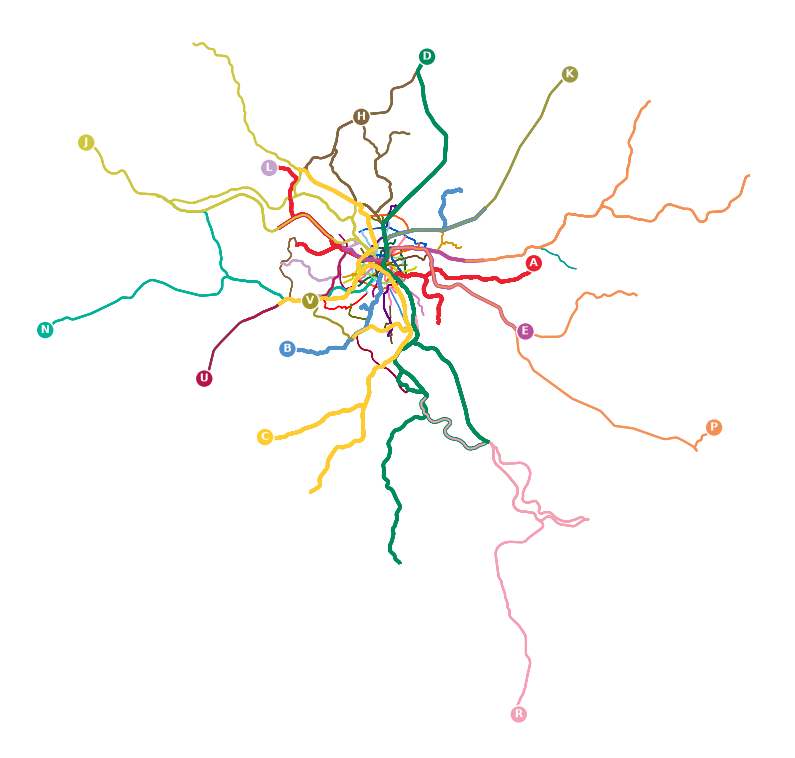

In [5]:
#NEW 

# ===== CARTE DU RÉSEAU =====
# Toutes les lignes (toutes les branches), sans les arrêts,
# avec le nom des lignes de train (RER + Transilien) au bout de chaque ligne
from shapely.geometry import Point

# Épaisseur du trait selon le type de ligne
EPAISSEUR = {"metro": 1, "tram": 0.8, "transilien": 1.5, "rer": 2.5}

ax = gpd_idfm.plot(
    color="#" + gpd_idfm["route_color"],
    linewidth=gpd_idfm["mode"].map(EPAISSEUR).values,
    figsize=(10, 10),
)

# Nom des lignes de train, placé au terminus le plus loin du centre de Paris
centre_paris = Point(651_000, 6_862_000)
trains = traces[traces["mode"].isin(["rer", "transilien"])]

for _, t in trains.iterrows():
    debut = Point(t.geometry.coords[0])
    fin = Point(t.geometry.coords[-1])
    bout = max([debut, fin], key=lambda p: p.distance(centre_paris))  # le bout le plus éloigné

    ax.annotate(
        t["route_short_name"], (bout.x, bout.y),
        ha="center", va="center", fontsize=8, fontweight="bold", color="white",
        bbox=dict(boxstyle="circle,pad=0.3", facecolor="#" + t["route_color"], edgecolor="white"),
        zorder=6,
    )

ax.set_axis_off()
plt.savefig("carte_lignes_idfm.png", dpi=300, bbox_inches="tight")
plt.show()

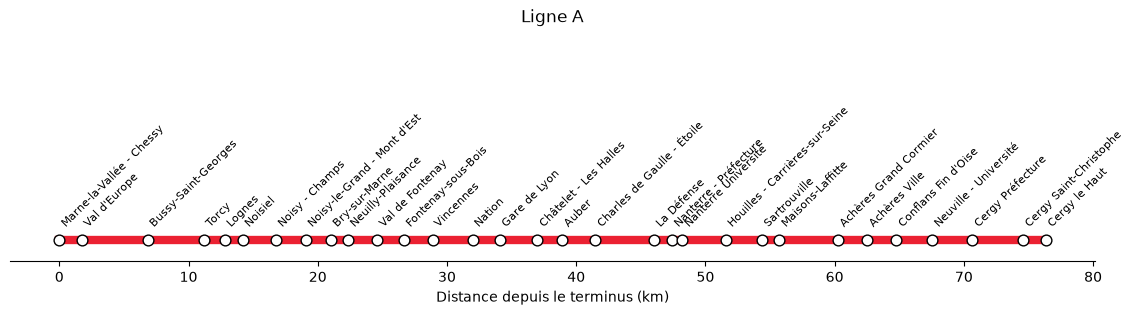

In [6]:
# ===== SCHÉMA D'UNE LIGNE =====
# La ligne "à plat", comme les plans dans le métro
num = "A"  # numéro de la ligne à afficher (rer ou metro)
arrets = stations[stations["route_short_name"] == num]
couleur = "#" + arrets["route_color"].iloc[0]

fig, ax = plt.subplots(figsize=(14, 3))
ax.plot(arrets["position_km"], [0] * len(arrets), color=couleur, linewidth=6)
ax.scatter(arrets["position_km"], [0] * len(arrets),
           color="white", edgecolor="black", s=60, zorder=3)

# Noms des stations, inclinés au-dessus de la ligne
for _, a in arrets.iterrows():
    ax.annotate(a["stop_name"], xy=(a["position_km"], 0), xytext=(0, 8),
                textcoords="offset points", rotation=45, fontsize=8,
                ha="left", va="bottom")

ax.set_title(f"Ligne {num}")
ax.set_xlabel("Distance depuis le terminus (km)")
ax.set_yticks([])
ax.set_ylim(-0.1, 1)
ax.spines[["left", "top", "right"]].set_visible(False)
plt.show()

# Partie 2 : Les actifs franciliens et leurs trajets (MOBPRO)

In [7]:
#  A 
#  CHARGEMENT ET PRÉPARATION DE MOBPRO 
df_mob = pd.read_parquet("RP2023_mobpro.parquet")

# On garde seulement l'Île-de-France (code région 11)
df_mob = df_mob[df_mob["REGION"].astype(str) == "11"].copy()

# Codes en texte, pour pouvoir les comparer aux dictionnaires
df_mob["COMMUNE"] = df_mob["COMMUNE"].astype(str)
df_mob["GS"] = df_mob["GS"].astype(str)        # GS = CSP
df_mob["TRANS"] = df_mob["TRANS"].astype(str)  # TRANS = mode de transport

# Noms en clair
noms_csp = {
    "1": "Agriculteurs",
    "2": "Artisans, commerçants, chefs d'entreprise",
    "3": "Cadres",
    "4": "Professions intermédiaires",
    "5": "Employés",
    "6": "Ouvriers",
}
noms_mode = {
    "1": "Pas de transport",
    "2": "Marche",
    "3": "Vélo",
    "4": "Deux-roues motorisé",
    "5": "Voiture",
    "6": "Transports en commun",
}
df_mob["CSP"] = df_mob["GS"].map(noms_csp)
df_mob["mode"] = df_mob["TRANS"].map(noms_mode)

# True si la personne va travailler en transports en commun
df_mob["tc"] = df_mob["mode"] == "Transports en commun"

# Code géographique : l'arrondissement si on habite Paris, sinon la commune
df_mob["code_geo"] = np.where(
    df_mob["COMMUNE"] == "75056", df_mob["ARM"].astype(str), df_mob["COMMUNE"]
)

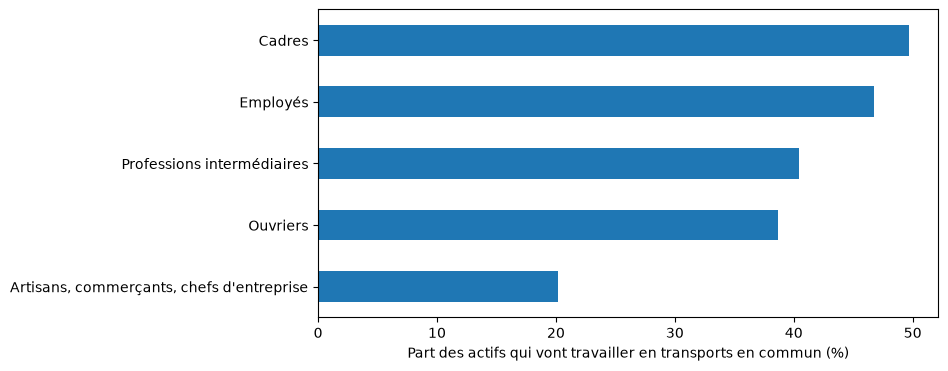

In [8]:
#  B 
#  PART DES TRANSPORTS EN COMMUN PAR CSP 
# Pondéré par IPONDI : chaque ligne représente plusieurs personnes réelles
df_mob["poids_tc"] = df_mob["IPONDI"] * df_mob["tc"]
somme = df_mob.groupby("CSP")[["poids_tc", "IPONDI"]].sum()
part_tc = somme["poids_tc"] / somme["IPONDI"] * 100

part_tc = part_tc.drop("Agriculteurs")  # trop peu nombreux pour être fiables

ax = part_tc.sort_values().plot(kind="barh", color="#1f77b4", figsize=(8, 4))
ax.set_xlabel("Part des actifs qui vont travailler en transports en commun (%)")
ax.set_ylabel("")
plt.show()

# Partie 3 : Croiser le réseau et la population

In [10]:
# C 
#  CONTOURS DES COMMUNES ET DES ARRONDISSEMENTS 

# Communes d'Île-de-France (fichier public GitHub)
url = "https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/regions/ile-de-france/communes-ile-de-france.geojson"
communes = gpd.read_file(url)
communes = communes.rename(columns={"code": "INSEE_COM"})
communes = communes.to_crs("EPSG:2154")[["INSEE_COM", "nom", "geometry"]]

# Arrondissements de Paris (open data de la Ville de Paris)
url_arr = "https://opendata.paris.fr/api/explore/v2.1/catalog/datasets/arrondissements/exports/geojson"
arr = gpd.read_file(url_arr)
arr = arr.rename(columns={"c_arinsee": "INSEE_COM"})
arr["INSEE_COM"] = arr["INSEE_COM"].astype(int).astype(str)  # ex : "75113"
arr["nom"] = arr["INSEE_COM"].str[-2:].astype(int).map(lambda n: "1er" if n == 1 else f"{n}ème")
arr = arr.to_crs("EPSG:2154")[["INSEE_COM", "nom", "geometry"]]

# On remplace "Paris" (75056) par ses 20 arrondissements
communes = pd.concat([communes[communes["INSEE_COM"] != "75056"], arr], ignore_index=True)

In [11]:
#  D
#  FONCTION - PART D'UN INDICATEUR PAR COMMUNE 

def part_par_zone(df_mob, indicateur):
    """Part (en %) d'un indicateur parmi les actifs de chaque commune
    (ou de chaque arrondissement pour Paris).
    indicateur : une CSP ("Ouvriers", "Cadres"...) ou "Transports en commun"."""
    # True pour les personnes concernées par l'indicateur
    if indicateur == "Transports en commun":
        cible = df_mob["tc"]
    else:
        cible = df_mob["CSP"] == indicateur

    # Part pondérée : poids des personnes concernées / poids de tous les actifs
    somme_cible = (df_mob["IPONDI"] * cible).groupby(df_mob["code_geo"]).sum()
    somme_total = df_mob.groupby("code_geo")["IPONDI"].sum()
    return (somme_cible / somme_total * 100).round(1).rename("part")

In [12]:
#  E 
#  COMMUNE DE CHAQUE STATION 
# Jointure géographique : on cherche la commune (ou l'arrondissement) qui contient chaque station
stations_com = gpd.sjoin(
    stations.drop(columns=["trace"]),  # colonne du tracé inutile ici
    communes,
    predicate="within",
)

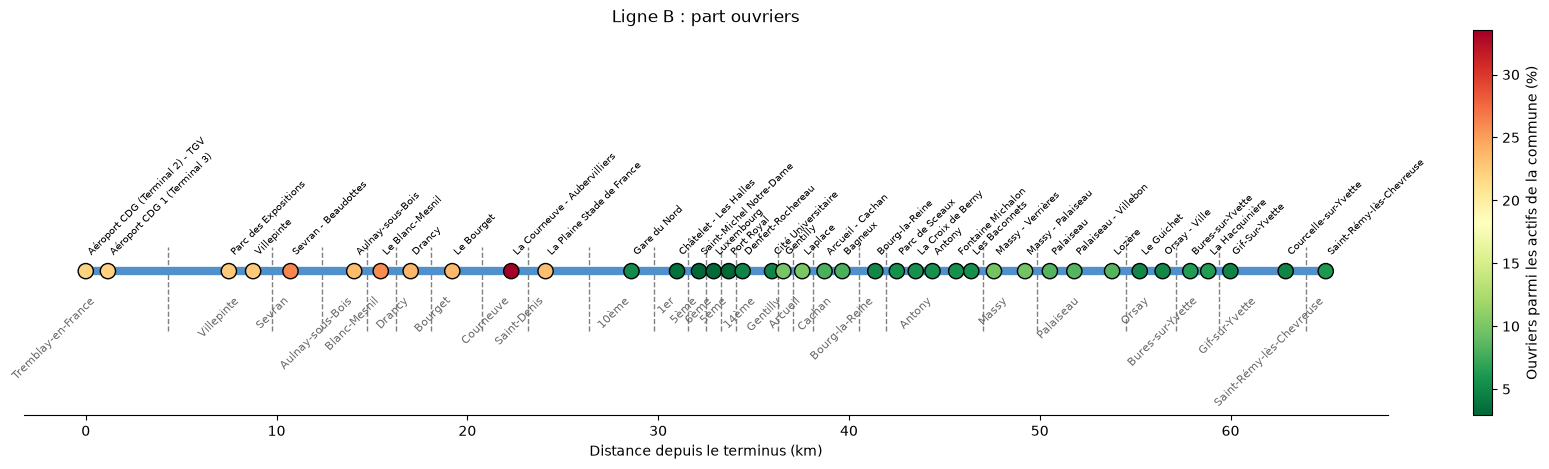

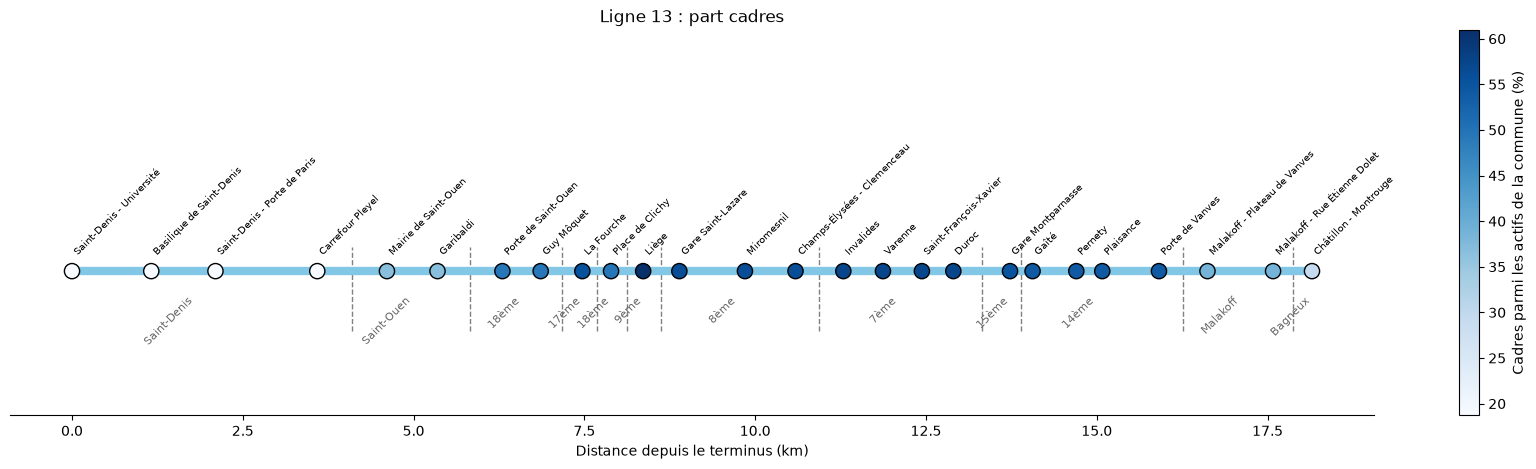

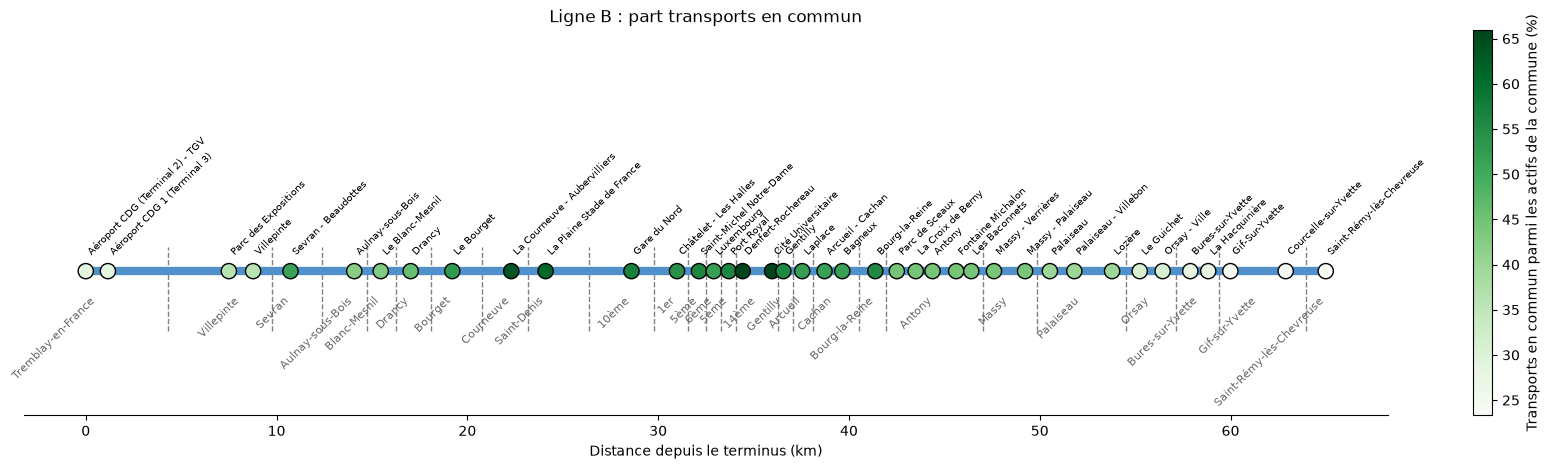

In [13]:
# F 
# FONCTION - SCHÉMA DE LIGNE COLORÉ PAR UN INDICATEUR 

def schema_ligne(num, indicateur="Ouvriers", cmap="RdYlGn_r"):
    """Schéma d'une ligne "à plat", stations colorées selon un indicateur.
    num        : numéro de la ligne ("13", "B"...)
    indicateur : une CSP ("Ouvriers", "Cadres"...) ou "Transports en commun" """

    # Stations de la ligne, dans l'ordre, avec la valeur de l'indicateur de leur commune
    part = part_par_zone(df_mob, indicateur)
    arrets = stations_com[stations_com["route_short_name"] == num]
    arrets = arrets.merge(part, left_on="INSEE_COM", right_index=True, how="left")
    arrets = arrets.sort_values("position_km").reset_index(drop=True)
    couleur = "#" + arrets["route_color"].iloc[0]

    fig, ax = plt.subplots(figsize=(22, 5))
    ax.plot(arrets["position_km"], [0] * len(arrets), color=couleur, linewidth=6, zorder=1)
    points = ax.scatter(
        arrets["position_km"], [0] * len(arrets),
        c=arrets["part"], cmap=cmap,
        s=120, edgecolor="black", zorder=2,
    )

    # Noms des stations, au-dessus
    for _, a in arrets.iterrows():
        ax.annotate(a["stop_name"], xy=(a["position_km"], 0), xytext=(0, 10),
                    textcoords="offset points", rotation=45, fontsize=7,
                    ha="left", va="bottom")

    # Délimitation des communes : un "bloc" = des stations consécutives dans la même commune
    arrets["bloc"] = (arrets["nom"] != arrets["nom"].shift()).cumsum()
    blocs = arrets.groupby("bloc").agg(
        nom=("nom", "first"),
        debut=("position_km", "min"),
        fin=("position_km", "max"),
    )

    # Trait pointillé à mi-chemin entre deux communes
    for i in range(len(blocs) - 1):
        frontiere = (blocs["fin"].iloc[i] + blocs["debut"].iloc[i + 1]) / 2
        ax.vlines(frontiere, -0.25, 0.1, color="gray", linestyle="--", linewidth=1, zorder=0)

    # Nom de la commune, en dessous
    for _, b in blocs.iterrows():
        ax.text((b["debut"] + b["fin"]) / 2, -0.1, b["nom"],
                rotation=45, ha="right", va="top", fontsize=8, color="dimgray")

    fig.colorbar(points, ax=ax, label=f"{indicateur} parmi les actifs de la commune (%)")
    ax.set_title(f"Ligne {num} : part {indicateur.lower()}")
    ax.set_xlabel("Distance depuis le terminus (km)")
    ax.set_ylim(-0.6, 1)
    ax.set_yticks([])
    ax.spines[["left", "top", "right"]].set_visible(False)
    plt.show()


# Exemples
schema_ligne("B", "Ouvriers")
schema_ligne("13", "Cadres", cmap="Blues")
schema_ligne("B", "Transports en commun", cmap="Greens")

In [14]:
# NEW

#  G 
#  FONCTION - CARTE DE PARIS OU DE L'ÎLE-DE-FRANCE =====

# Contours des départements : on fusionne les communes selon les 2 premiers chiffres du code
communes["dep"] = communes["INSEE_COM"].str[:2]
departements = communes.dissolve(by="dep").reset_index()[["dep", "geometry"]]


def carte(indicateur="Ouvriers", zone="paris", ligne=None, reseau=False, cmap="Reds"):
    """Carte colorée selon un indicateur (en % des actifs).
    zone   : "paris" (20 arrondissements) ou "idf" (toutes les communes)
    ligne  : numéro d'une ligne à superposer, par exemple "13" ou "P" (facultatif)
    reseau : True pour tout le réseau, ou une liste de types, ex. ["rer", "transilien"]"""

    # 1. Le fond de carte selon la zone choisie
    if zone == "paris":
        fond = arr
    elif zone == "idf":
        fond = communes
    else:
        raise ValueError('zone doit valoir "paris" ou "idf"')

    # On ajoute la valeur de l'indicateur à chaque zone
    part = part_par_zone(df_mob, indicateur)
    fond = fond.merge(part, left_on="INSEE_COM", right_index=True, how="left")

    ax = fond.plot(
        column="part", cmap=cmap, legend=True,
        edgecolor="white",
        linewidth=0.8 if zone == "paris" else 0.1,  # traits fins pour les 1 300 communes
        figsize=(12, 10),
        missing_kwds={"color": "lightgrey"},  # gris si pas de donnée
        legend_kwds={"label": f"{indicateur} parmi les actifs (%)", "shrink": 0.6},
    )

    # 2a. Paris : nom et valeur de chaque arrondissement
    if zone == "paris":
        for _, r in fond.iterrows():
            p = r.geometry.representative_point()
            ax.annotate(f"{r['nom']}\n{r['part']} %", (p.x, p.y),
                        ha="center", va="center", fontsize=7)

    # 2b. IDF : contours des départements en noir + leur numéro
    if zone == "idf":
        departements.boundary.plot(ax=ax, color="black", linewidth=1, zorder=2)
        for _, d in departements.iterrows():
            p = d.geometry.representative_point()
            ax.annotate(d["dep"], (p.x, p.y), ha="center", va="center",
                        fontsize=11, fontweight="bold", color="black")

    # 3a. Le réseau (facultatif), sans les arrêts
    if reseau:
        lignes = gpd_idfm if reseau is True else gpd_idfm[gpd_idfm["mode"].isin(reseau)]
        epaisseur = lignes["mode"].map(EPAISSEUR).values  # EPAISSEUR est défini en Partie 1
        lignes.plot(ax=ax, color="white", linewidth=epaisseur + 1.5, zorder=3)  # liseré blanc
        lignes.plot(ax=ax, color="#" + lignes["route_color"], linewidth=epaisseur, zorder=4)

    # 3b. Une seule ligne (facultative), avec un liseré blanc, et ses stations
    if ligne is not None:
        trace = gpd_idfm[gpd_idfm["route_short_name"] == ligne]
        trace.plot(ax=ax, color="white", linewidth=7, zorder=3)
        trace.plot(ax=ax, color="#" + trace["route_color"].iloc[0], linewidth=4, zorder=4)
        gpd_stations[gpd_stations["route_short_name"] == ligne].plot(
            ax=ax, color="white", edgecolor="black", markersize=30, zorder=5
        )

    # 4. Cadrage sur la zone (marge de 500 m)
    xmin, ymin, xmax, ymax = fond.total_bounds
    ax.set_xlim(xmin - 500, xmax + 500)
    ax.set_ylim(ymin - 500, ymax + 500)

    # Titre
    nom_zone = "Paris" if zone == "paris" else "Île-de-France"
    titre = f"Part {indicateur.lower()} parmi les actifs ({nom_zone})"
    if ligne is not None:
        titre += f" - ligne {ligne}"
    if reseau:
        titre += " - réseau"
    ax.set_title(titre)
    ax.set_axis_off()
    plt.show()

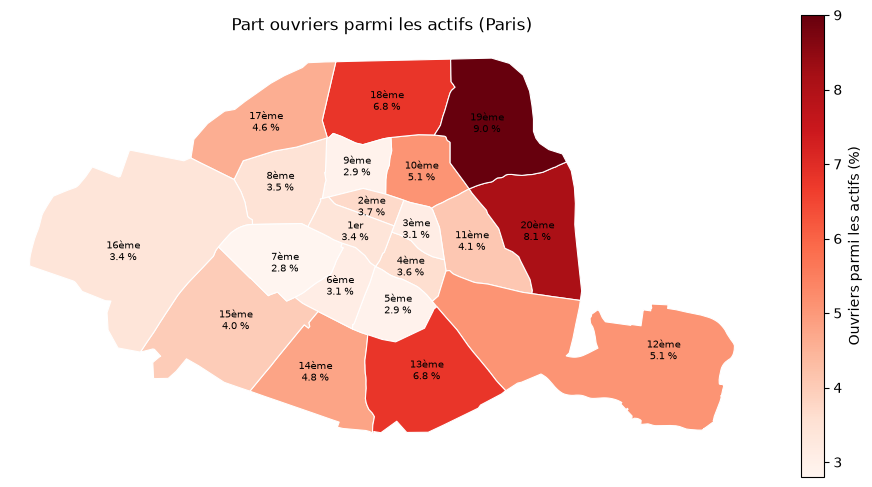

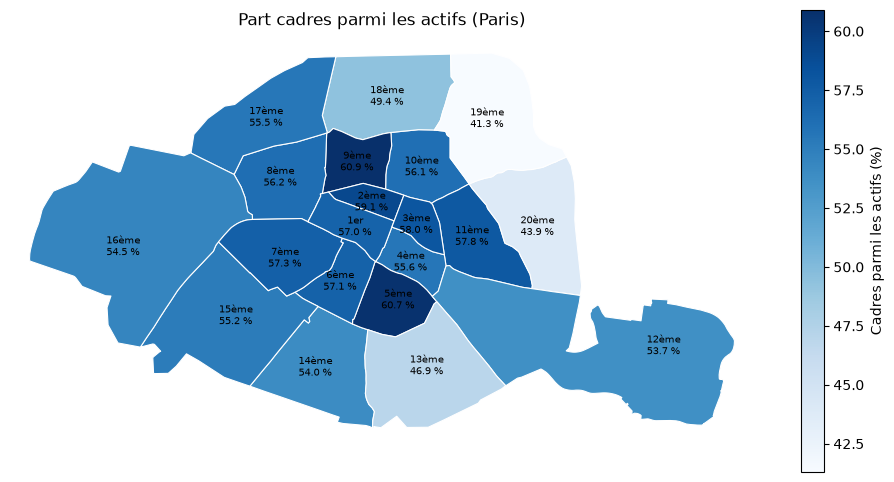

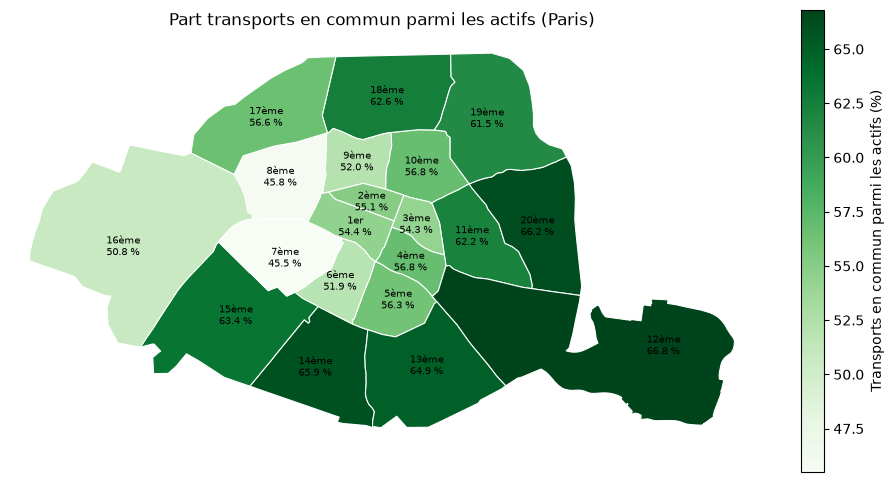

In [ ]:
#  H 
#  CARTES 

# --- 1. Paris par arrondissement : les 3 indicateurs principaux ---
carte("Ouvriers", zone="paris")
carte("Cadres", zone="paris", cmap="Blues")
carte("Transports en commun", zone="paris", cmap="Greens")


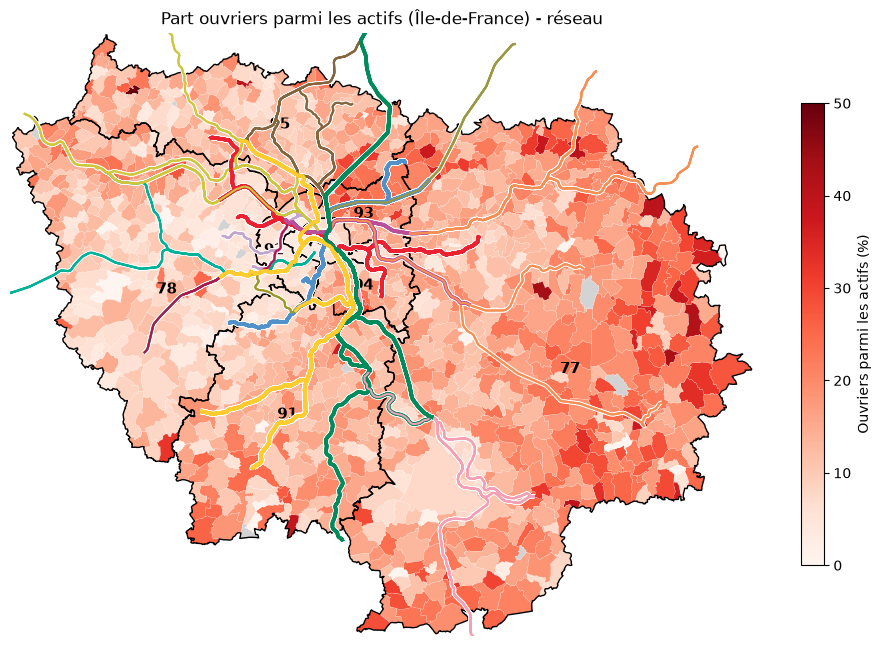

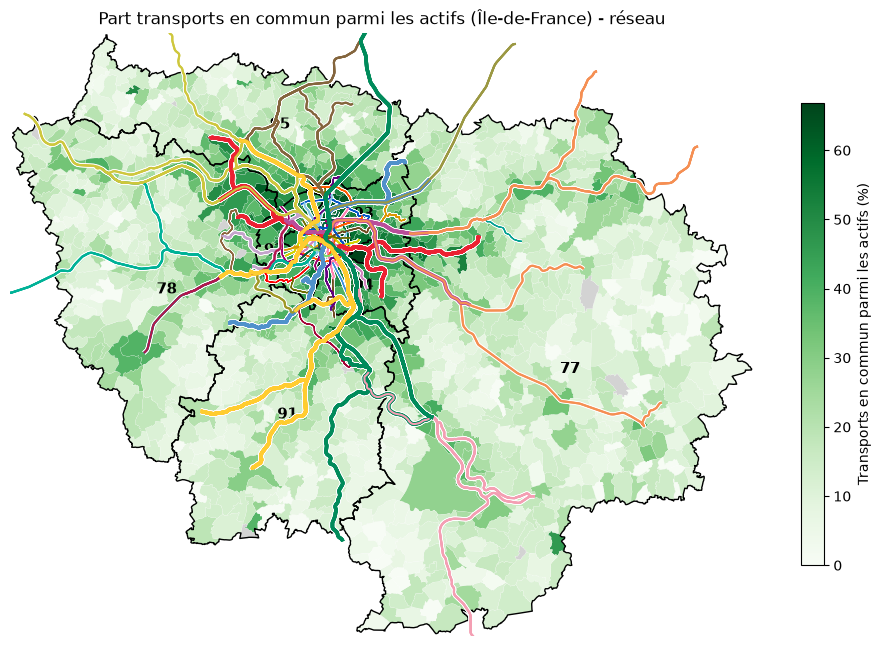

In [ ]:
# H bis

# --- 2. Île-de-France avec le réseau ---
carte("Ouvriers", zone="idf", reseau=["rer", "transilien"])        # tous les trains
carte("Transports en commun", zone="idf", reseau=True, cmap="Greens")  # tout le réseau



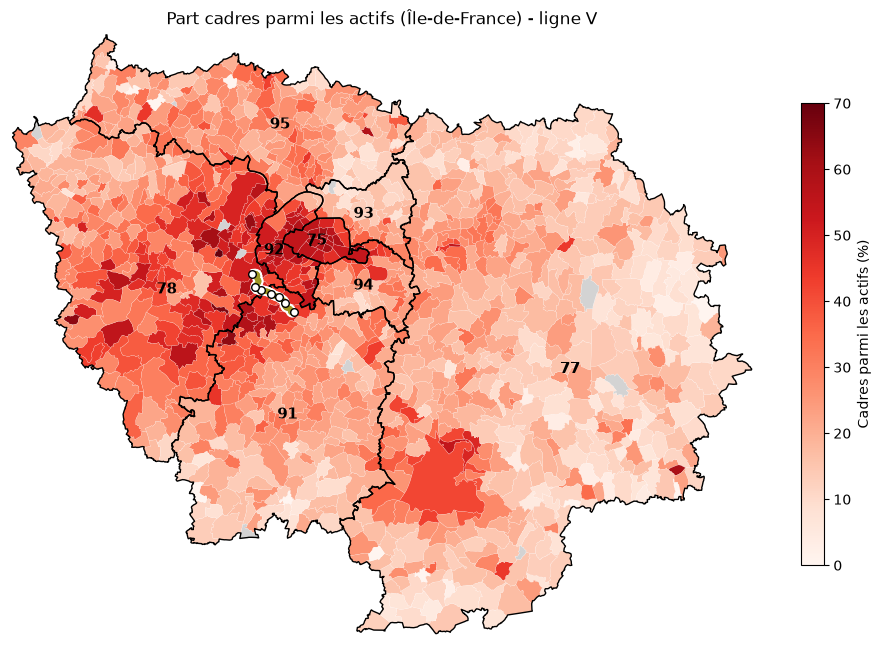

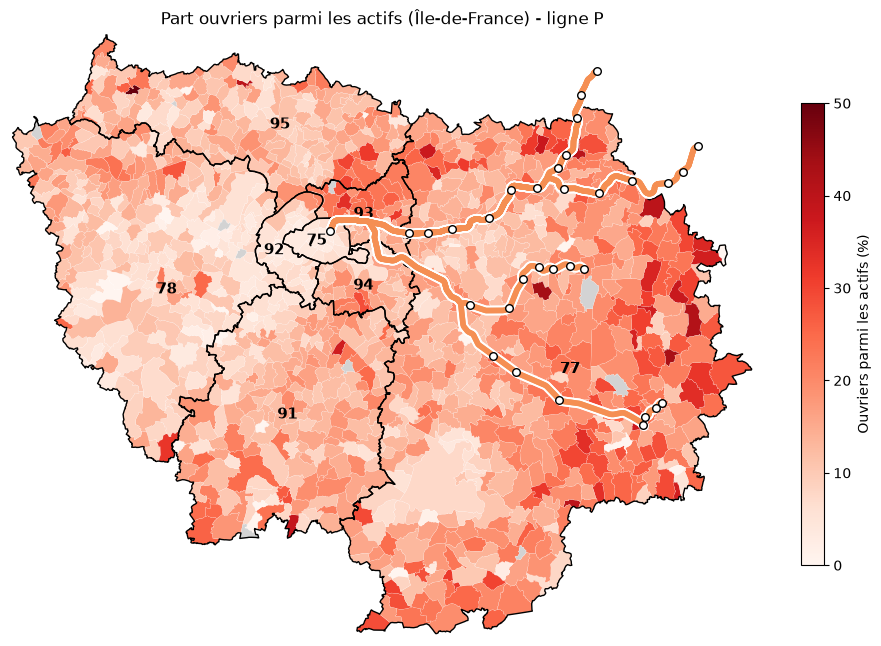

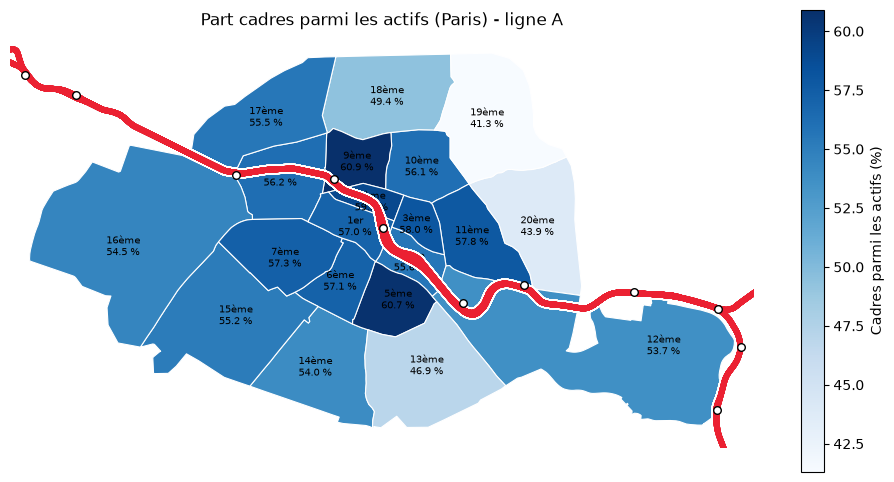

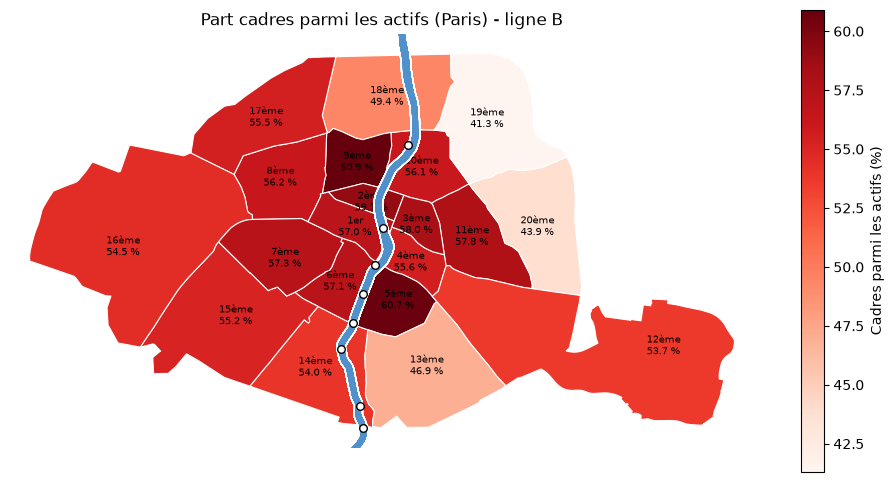

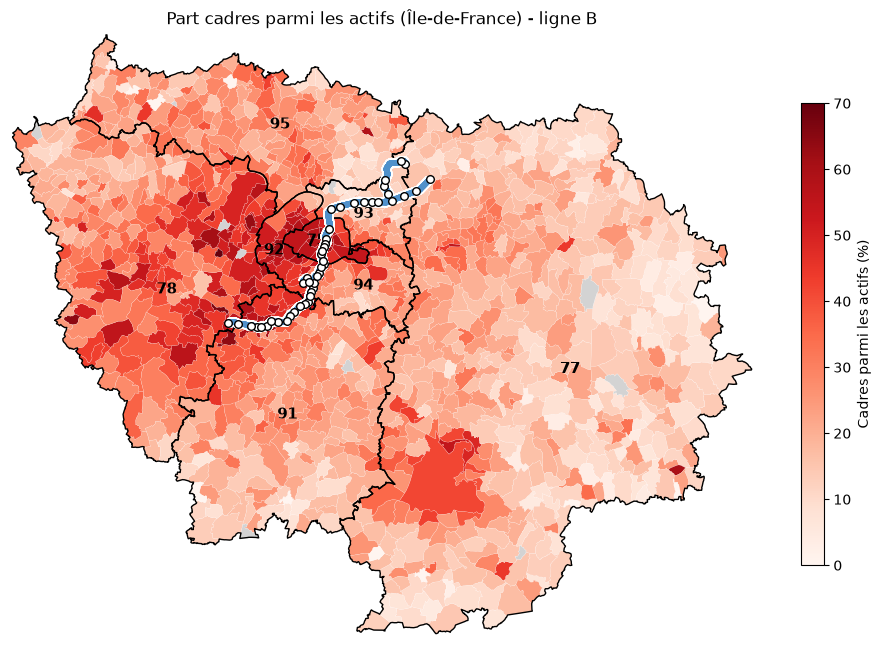

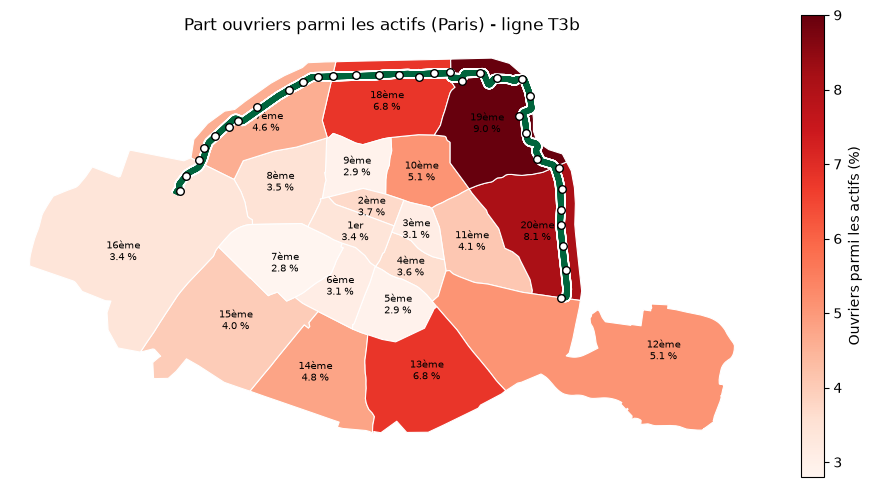

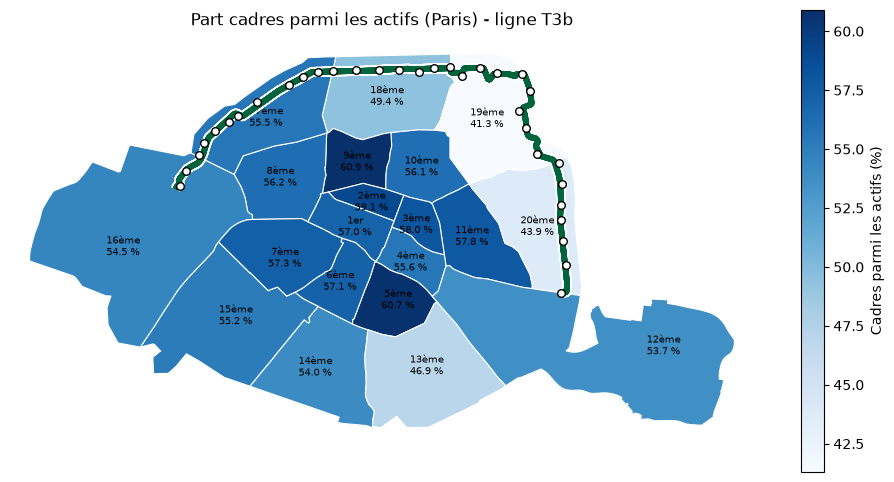

In [ ]:
# H bis bis 

carte("Cadres", zone="idf", ligne="V")   
carte("Ouvriers", zone="idf", ligne="P")                   # Transilien
carte("Cadres", zone="paris", ligne="A", cmap="Blues")      # métro, sur Paris

#ligne B
carte("Cadres", ligne = "B")
carte ("Cadres", zone="idf", ligne="B")

#tram
carte("Ouvriers", zone="paris", ligne="T3b")                
carte("Cadres", zone="paris", ligne="T3b", cmap="Blues")

# Partie 4 : Temps de trajet réel et distance à Châtelet

In [27]:
# ===== CELLULE I : IMPORTS ET GRAPHE DU RÉSEAU =====
from pretraitement_donnees import (
    charger_horaires, construire_aretes, construire_graphe_reseau, construire_stations,
)
from analyse_donnees import calculer_temps_trajet

# Graphe du réseau : stations = points, trajets entre stations = traits pondérés par le temps
df_horaires = charger_horaires("data/idfm", df_trips)
df_aretes = construire_aretes(df_horaires)
graphe_reseau = construire_graphe_reseau(df_aretes)

# Une ligne par station (et non une par couple station-ligne)
stations_uniques = construire_stations(df_stations)

In [28]:
# ===== CELLULE J : TEMPS DE TRAJET ET DISTANCE À CHÂTELET =====

# Destination : Châtelet (métro) et Châtelet - Les Halles (RER)
destinations = stations_uniques.loc[
    stations_uniques["stop_name"].isin(["Châtelet - Les Halles", "Châtelet"]), "stop_id"
]

# Temps de trajet minimal (en minutes) de chaque station vers Châtelet
df_temps = calculer_temps_trajet(graphe_reseau, destinations)

# Distance à vol d'oiseau jusqu'à Châtelet - Les Halles (en km, Lambert 93 = mètres)
chatelet = stations_uniques.loc[
    stations_uniques["stop_name"] == "Châtelet - Les Halles", "geometry"
].iloc[0]
df_reg = stations_uniques.merge(df_temps, on="stop_id")
df_reg["distance_km"] = df_reg.distance(chatelet) / 1000

# On retire Châtelet lui-même (temps = 0)
df_reg = df_reg[df_reg["temps_trajet"] > 0]
df_reg[["stop_name", "distance_km", "temps_trajet"]].sort_values("distance_km")

,stop_name,distance_km,temps_trajet
462,Les Halles,0.133701,0.833333
862,Étienne Marcel,0.303777,1.683333
715,Pont Neuf,0.421843,1.150000
530,Louvre - Rivoli,0.474706,0.900000
711,Rambuteau,0.481311,1.500000
...,...,...,...
106,Château-Thierry,80.249220,63.950000
91,Souppes - Château-Landon,80.850526,71.633333
52,Dordives,85.103077,75.800000
95,Ferrières - Fontenay,90.723263,80.633333


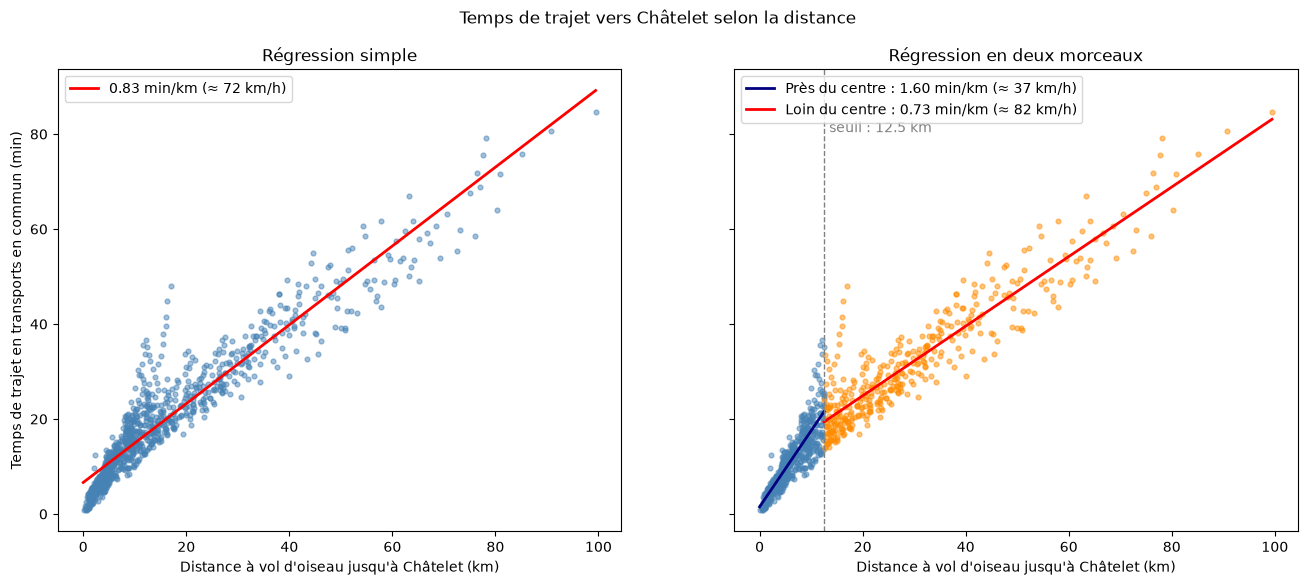

In [29]:
# ===== CELLULE K : RÉGRESSION SIMPLE ET RÉGRESSION EN DEUX MORCEAUX =====
x = df_reg["distance_km"].values
y = df_reg["temps_trajet"].values

# --- Régression simple : une seule droite ---
pente, constante = np.polyfit(x, y, 1)


# --- Régression en deux morceaux : on cherche le meilleur seuil ---
def erreur_totale(seuil):
    """Erreur des deux droites (avant / après le seuil) : plus elle est petite, mieux elles collent"""
    erreur = 0
    for masque in [x < seuil, x >= seuil]:
        p, c = np.polyfit(x[masque], y[masque], 1)
        erreur += ((y[masque] - (c + p * x[masque])) ** 2).sum()
    return erreur


seuils = np.arange(5, 40.5, 0.5)
seuil = seuils[np.argmin([erreur_totale(s) for s in seuils])]
pres, loin = x < seuil, x >= seuil
pente1, const1 = np.polyfit(x[pres], y[pres], 1)
pente2, const2 = np.polyfit(x[loin], y[loin], 1)

# --- Les deux graphiques côte à côte ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

# Gauche : une seule droite
ax1.scatter(x, y, s=12, alpha=0.5, color="steelblue")
x_ligne = np.linspace(0, x.max(), 100)
ax1.plot(x_ligne, constante + pente * x_ligne, color="red", linewidth=2,
         label=f"{pente:.2f} min/km (≈ {60 / pente:.0f} km/h)")
ax1.set_title("Régression simple")

# Droite : deux régimes
ax2.scatter(x[pres], y[pres], s=12, alpha=0.5, color="steelblue")
ax2.scatter(x[loin], y[loin], s=12, alpha=0.5, color="darkorange")
x1, x2 = np.linspace(0, seuil, 50), np.linspace(seuil, x.max(), 50)
ax2.plot(x1, const1 + pente1 * x1, color="navy", linewidth=2,
         label=f"Près du centre : {pente1:.2f} min/km (≈ {60 / pente1:.0f} km/h)")
ax2.plot(x2, const2 + pente2 * x2, color="red", linewidth=2,
         label=f"Loin du centre : {pente2:.2f} min/km (≈ {60 / pente2:.0f} km/h)")
ax2.axvline(seuil, color="gray", linestyle="--", linewidth=1)
ax2.text(seuil + 1, y.max() * 0.95, f"seuil : {seuil:.1f} km", color="gray")
ax2.set_title("Régression en deux morceaux")

# Mise en forme commune
for ax in (ax1, ax2):
    ax.set_xlabel("Distance à vol d'oiseau jusqu'à Châtelet (km)")
    ax.legend(loc="upper left")
ax1.set_ylabel("Temps de trajet en transports en commun (min)")
fig.suptitle("Temps de trajet vers Châtelet selon la distance")
plt.show()

> Le seuil de 12,5 km correspond à la limite de la petite couronne : en deçà, le métro dessert finement le territoire mais lentement (1,6 min par km) ; au-delà, seuls le RER et le Transilien prennent le relais, plus rapides (0,7 min par km) mais moins bien répartis. Les communes situées juste après cette limite sont les plus pénalisées : trop loin pour le métro, parfois mal reliées au RER, elles connaissent les temps de trajet les plus élevés au regard de leur distance à Paris.

In [30]:
# ===== CELLULE L : DÉCOUVRIR FILOSOFI =====
from pretraitement_donnees import charger_filosofi, indicateurs_filosofi

# Carreaux de 200 m d'Île-de-France (lecture : 1 à 2 minutes)
df_filosofi = charger_filosofi("data/filosofi/france_metro/carreaux_200m_met.shp")
df_filosofi = indicateurs_filosofi(df_filosofi)  # ajoute nv = niveau de vie moyen par habitant

print("Nombre de carreaux :", len(df_filosofi))
print("Colonnes :", df_filosofi.columns.tolist())
print()
print(df_filosofi[["ind", "ind_snv", "nv"]].describe().round(0))
df_filosofi.head()

Nombre de carreaux : 72766
Colonnes : ['lcog_geo', 'ind', 'ind_snv', 'geometry', 'nv']

           ind      ind_snv       nv
count  72766.0      72766.0  72766.0
mean     163.0    4642261.0  29868.0
std      292.0    8782956.0   7024.0
min        1.0      14381.0   9461.0
25%       10.0     310431.0  25429.0
50%       52.0    1561070.0  29106.0
75%      178.0    5130676.0  33432.0
max     7546.0  122842708.0  73664.0


,lcog_geo,ind,ind_snv,geometry,nv
1550427,"77099,45255,45114",3.0,73610.5,"POLYGON ((675221.847 6780022.874, 675203.377 6...",24536.833333
1551095,"77099,45255",2.0,55295.1,"POLYGON ((676995.101 6780392.708, 676976.633 6...",27647.550000
1551746,"77099,45255",7.0,155117.9,"POLYGON ((675583.068 6780458.731, 675564.598 6...",22159.700000
1551747,77099,7.0,177031.0,"POLYGON ((676976.633 6780591.648, 676958.164 6...",25290.142857
1552403,77099,5.0,110798.5,"POLYGON ((676161.841 6780714.637, 676143.371 6...",22159.700000


Le **niveau de vie** (Insee, Filosofi) correspond au revenu disponible d'un ménage (revenus, aides sociales, impôts déduits), divisé par le nombre d'unités de consommation pour tenir compte de sa taille. Il s'exprime en euros par an et par personne.

In [31]:
# ===== CELLULE M : DISTANCE ET TEMPS DE TRAJET POUR CHAQUE CARREAU =====
from pretraitement_donnees import construire_centres_carreaux
from analyse_donnees import joindre_carreaux_stations

# Centre de chaque carreau de 200 m
centres = construire_centres_carreaux(df_filosofi)

# Temps total vers Châtelet = marche jusqu'à la station la plus proche + transports
# (au-delà de 1,5 km d'une station, le carreau est "non desservi" : temps vide)
carreaux = joindre_carreaux_stations(
    centres, stations_uniques, df_temps, distance_max=1500, vitesse_marche=75
)

# Distance à vol d'oiseau jusqu'à Châtelet (en km)
carreaux["distance_km"] = carreaux.distance(chatelet) / 1000

print("Carreaux :", len(carreaux))
print("Carreaux desservis (avec un temps) :", carreaux["temps_total"].notna().sum())

Carreaux : 72766
Carreaux desservis (avec un temps) : 34569


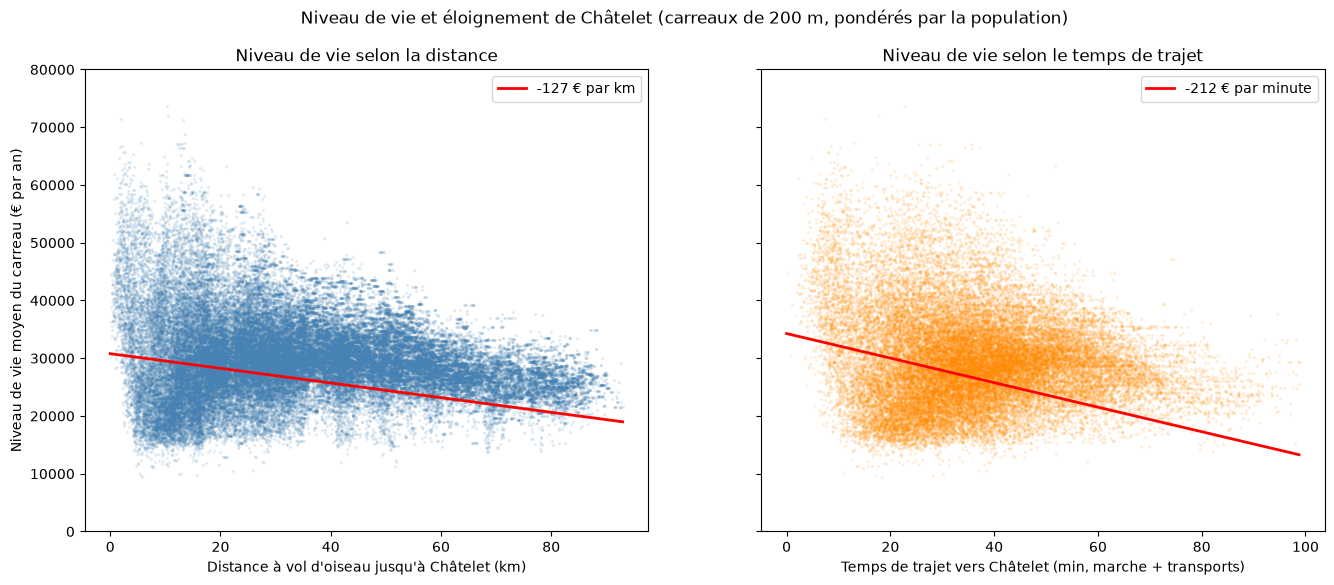

Distance : 1 km de plus = -127 € de niveau de vie par an
Temps : 1 minute de plus = -212 € de niveau de vie par an

Niveau de vie ~ distance
                 Coef.  Std.Err.  P>|t|
Intercept    30793.868    50.432    0.0
distance_km   -126.929     2.197    0.0
R² = 0.044

Niveau de vie ~ temps
                 Coef.  Std.Err.  P>|t|
Intercept    34274.141   103.936    0.0
temps_total   -212.442     3.591    0.0
R² = 0.092



In [32]:
# ===== CELLULE N : NIVEAU DE VIE SELON LA DISTANCE ET SELON LE TEMPS =====


def regression_ponderee(x, y, poids):
    """Droite y = constante + pente * x, où chaque point compte selon son poids (habitants)"""
    # np.polyfit attend la racine des poids
    pente, constante = np.polyfit(x, y, 1, w=np.sqrt(poids))
    return pente, constante


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

# --- Gauche : niveau de vie selon la distance (tous les carreaux) ---
d = carreaux.dropna(subset=["distance_km", "nv"])
pente_d, const_d = regression_ponderee(d["distance_km"], d["nv"], d["ind"])
ax1.scatter(d["distance_km"], d["nv"], s=2, alpha=0.1, color="steelblue")
x_ligne = np.linspace(0, d["distance_km"].max(), 100)
ax1.plot(x_ligne, const_d + pente_d * x_ligne, color="red", linewidth=2,
         label=f"{pente_d:+.0f} € par km")
ax1.set_xlabel("Distance à vol d'oiseau jusqu'à Châtelet (km)")
ax1.set_title("Niveau de vie selon la distance")

# --- Droite : niveau de vie selon le temps (carreaux desservis seulement) ---
t = carreaux.dropna(subset=["temps_total", "nv"])
pente_t, const_t = regression_ponderee(t["temps_total"], t["nv"], t["ind"])
ax2.scatter(t["temps_total"], t["nv"], s=2, alpha=0.1, color="darkorange")
x_ligne = np.linspace(0, t["temps_total"].max(), 100)
ax2.plot(x_ligne, const_t + pente_t * x_ligne, color="red", linewidth=2,
         label=f"{pente_t:+.0f} € par minute")
ax2.set_xlabel("Temps de trajet vers Châtelet (min, marche + transports)")
ax2.set_title("Niveau de vie selon le temps de trajet")

# Mise en forme commune
for ax in (ax1, ax2):
    ax.legend(loc="upper right")
ax1.set_ylabel("Niveau de vie moyen du carreau (€ par an)")
ax1.set_ylim(0, 80_000)  # on coupe les quelques carreaux extrêmes pour la lisibilité
fig.suptitle("Niveau de vie et éloignement de Châtelet (carreaux de 200 m, pondérés par la population)")
plt.show()

print(f"Distance : 1 km de plus = {pente_d:+.0f} € de niveau de vie par an")
print(f"Temps : 1 minute de plus = {pente_t:+.0f} € de niveau de vie par an")
print()

# --- Tableau des résultats (constante, pente, écart-type, p-value, R²) ---
import statsmodels.formula.api as smf

for nom, donnees, variable in [("Niveau de vie ~ distance", d, "distance_km"),
                               ("Niveau de vie ~ temps", t, "temps_total")]:
    m = smf.wls(f"nv ~ {variable}", data=donnees, weights=donnees["ind"]).fit()
    print(nom)
    print(m.summary2().tables[1][["Coef.", "Std.Err.", "P>|t|"]].round(3))
    print(f"R² = {m.rsquared:.3f}\n")

Le niveau de vie diminue significativement avec l'éloignement de Châtelet : −127 € par an pour chaque kilomètre, et −212 € pour chaque minute de trajet supplémentaire. Le temps de trajet explique deux fois mieux les écarts de niveau de vie que la distance (R² de 9,2 % contre 4,4 %), ce qui suggère que l'accessibilité réelle compte davantage que l'éloignement géographique. Ces deux variables n'expliquent toutefois qu'une faible part des inégalités, qui dépendent surtout de la localisation des quartiers (ouest aisé, nord-est plus modeste).